## Precision-Recall: примеры с сайта scikit-learn.org

In [88]:
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

X, y = load_iris(return_X_y=True)

# Add noisy features
random_state = np.random.RandomState(0)
n_samples, n_features = X.shape
X = np.concatenate([X, random_state.randn(n_samples, 200 * n_features)], axis=1)

# Limit to the two first classes, and split into training and test
X_train, X_test, y_train, y_test = train_test_split(
    X[y < 2], y[y < 2], test_size=0.5, random_state=random_state
)

In [89]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

classifier = make_pipeline(StandardScaler(), LinearSVC(random_state=random_state))
classifier.fit(X_train, y_train)

,steps,"[('standardscaler', ...), ('linearsvc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001


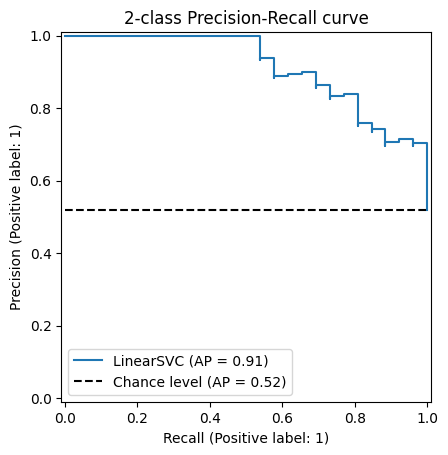

In [90]:
from sklearn.metrics import PrecisionRecallDisplay

display = PrecisionRecallDisplay.from_estimator(
    classifier, X_test, y_test, name="LinearSVC", plot_chance_level=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

Переход от бинарного примера к мультиклассу (и вообще multi-label) через схему one-vs-rest (OvR).

In [91]:
from sklearn.preprocessing import label_binarize

# Use label_binarize to be multi-label like settings
Y = label_binarize(y, classes=[0, 1, 2])
n_classes = Y.shape[1]

# Split into training and test
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.5, random_state=random_state
)

In [92]:
from sklearn.multiclass import OneVsRestClassifier

classifier = OneVsRestClassifier(
    make_pipeline(StandardScaler(), LinearSVC(random_state=random_state))
)
classifier.fit(X_train, Y_train)
y_score = classifier.decision_function(X_test)

In [93]:
from sklearn.metrics import average_precision_score, precision_recall_curve

# For each class
precision = dict()
recall = dict()
average_precision = dict()
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(Y_test[:, i], y_score[:, i])
    average_precision[i] = average_precision_score(Y_test[:, i], y_score[:, i])

# A "micro-average": quantifying score on all classes jointly
precision["micro"], recall["micro"], _ = precision_recall_curve(
    Y_test.ravel(), y_score.ravel()
)
average_precision["micro"] = average_precision_score(Y_test, y_score, average="micro")

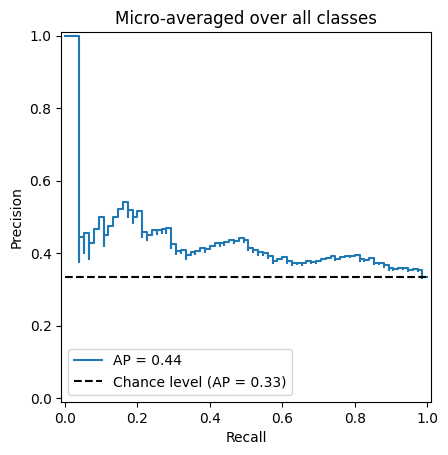

In [94]:
from collections import Counter

display = PrecisionRecallDisplay(
    recall=recall["micro"],
    precision=precision["micro"],
    average_precision=average_precision["micro"],
    prevalence_pos_label=Counter(Y_test.ravel())[1] / Y_test.size,
)
display.plot(plot_chance_level=True)
_ = display.ax_.set_title("Micro-averaged over all classes")

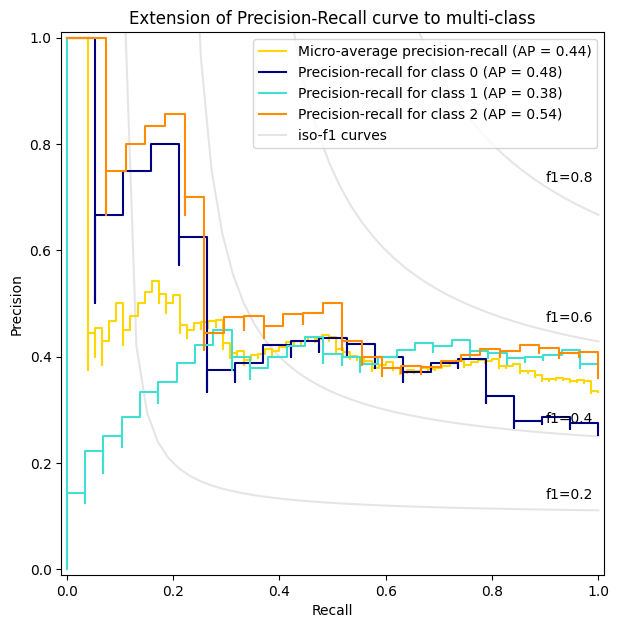

In [95]:
from itertools import cycle

import matplotlib.pyplot as plt

# setup plot details
colors = cycle(["navy", "turquoise", "darkorange", "cornflowerblue", "teal"])

_, ax = plt.subplots(figsize=(7, 8))

f_scores = np.linspace(0.2, 0.8, num=4)
lines, labels = [], []
for f_score in f_scores:
    x = np.linspace(0.01, 1)
    y = f_score * x / (2 * x - f_score)
    (l,) = plt.plot(x[y >= 0], y[y >= 0], color="gray", alpha=0.2)
    plt.annotate("f1={0:0.1f}".format(f_score), xy=(0.9, y[45] + 0.02))

display = PrecisionRecallDisplay(
    recall=recall["micro"],
    precision=precision["micro"],
    average_precision=average_precision["micro"],
)
display.plot(ax=ax, name="Micro-average precision-recall", color="gold")

for i, color in zip(range(n_classes), colors):
    display = PrecisionRecallDisplay(
        recall=recall[i],
        precision=precision[i],
        average_precision=average_precision[i],
    )
    display.plot(ax=ax, name=f"Precision-recall for class {i}", color=color)

# add the legend for the iso-f1 curves
handles, labels = display.ax_.get_legend_handles_labels()
handles.extend([l])
labels.extend(["iso-f1 curves"])
# set the legend and the axes
ax.legend(handles=handles, labels=labels, loc="best")
ax.set_title("Extension of Precision-Recall curve to multi-class")

plt.show()

# Precision-Recall кривая

В рамках этой задачи необходимо реализовать функицию, которая будет строить Precision-Recall кривую (в частности, точки, через которые проходит кривая) для заданной выборки. Описание можно найти в документации sklearn: [PR curve](https://scikit-learn.org/1.5/auto_examples/model_selection/plot_precision_recall.html)

Обращаем ваше внимание, график всегда проходит через точку (0, 1), поэтому возвращаемый массив также должен содержать эту точку.

Ваша задача: реализовать функцию ниже, которая находит решение для задачи линейной регрессии в указанных ограничениях.

In [96]:
import numpy as np


def build_precision_recall_curve(
    true_labels: np.ndarray, predicted_probas: np.ndarray
) -> np.ndarray:
    """
    Данная функция строит PR-кривую для задачи бинарной классификации.
    В случае, когда нет ни одного объекта положительного класса функция должна вызывать ValueError().

    Args:
        true_labels (np.ndarray): Массив истинных меток класса. Состоит из 0 и 1.
            1 считается меткой положительного класса.
        predicted_probas (np.ndarray): Массив предсказанных вероятностей принадлежности объекта
            к положительному классу.

    Returns:
        np.ndarray: Массив размерами (len(true_labels)+1, 2), где в каждой строчке стоит пара (recall,precision), первым элементом всегда идет (0, 1)
    """

    y = np.asarray(true_labels).astype(int).ravel()
    p = np.asarray(predicted_probas).astype(float).ravel()

    P = y.sum()
    n = y.size

    #assert y.shape == p.shape
    #assert set(y) == {0, 1} 

    if n == 0:
        return np.array([[0.0, 1.0]], dtype=np.float64)
    if P == 0:
        raise ValueError()

    precision_k = np.empty(n, dtype=float)
    recall_k    = np.empty(n, dtype=float)

    thresholds = np.sort(p)[::-1]

    for i in range(n):
        t = thresholds[i]
        pred_pos = (p >= t) 
        tp = np.sum(pred_pos & (y == 1))
        fp = np.sum(pred_pos & (y == 0))
        fn = P - tp 

        precision_k[i] = tp / (tp + fp)
        recall_k[i] =    tp / (tp + fn)

    
    out = np.empty((n+1, 2), dtype=np.float64)
    out[0] = (0.0, 1.0) 
    out[1:, 0] = recall_k
    out[1:, 1] = precision_k
    return out    

Ниже приведен один из тестов для локальной проверки решения:

In [97]:
true_labels = np.array([0, 0, 1, 1])
predicted_probas = np.array([0.1, 0.4, 0.35, 0.8])
expected = np.array([[0.0, 1.0], [0.5, 1.0], [0.5, 0.5], [1.0, 0.66666667], [1.0, 0.5]])
result = build_precision_recall_curve(true_labels, predicted_probas)
assert np.allclose(result, expected, atol=1e-6)

In [98]:
import numpy as np

def _assert_raises(fn, *args, **kwargs):
    try:
        fn(*args, **kwargs)
    except Exception:
        return
    raise AssertionError("Ожидали исключение, но его не было")

# --- 1) Тест из условия ---
y = np.array([0, 0, 1, 1])
p = np.array([0.1, 0.4, 0.35, 0.8])
expected = np.array([
    [0.0, 1.0],
    [0.5, 1.0],
    [0.5, 0.5],
    [1.0, 0.66666667],
    [1.0, 0.5],
])
res = build_precision_recall_curve(y, p)
assert np.allclose(res, expected, atol=1e-6)

# --- 2) Уникальные скоры, явный расчёт ---
y = np.array([1, 0, 1, 0])
p = np.array([0.9, 0.7, 0.6, 0.1])  # пороги: 0.9, 0.7, 0.6, 0.1
expected = np.array([
    [0.0, 1.0],   # стартовая фиктивная точка
    [0.5, 1.0],   # t=0.9  -> TP=1, FP=0
    [0.5, 0.5],   # t=0.7  -> TP=1, FP=1
    [1.0, 2/3],   # t=0.6  -> TP=2, FP=1
    [1.0, 0.5],   # t=0.1  -> TP=2, FP=2
])
res = build_precision_recall_curve(y, p)
assert np.allclose(res, expected, atol=1e-6)

# --- 3) Тай-брейки по скору (дубликаты допустимы) ---
y = np.array([1, 0, 1, 0])
p = np.array([0.7, 0.7, 0.6, 0.2])
expected = np.array([
    [0.0, 1.0],
    [0.5, 0.5],   # первый 0.7
    [0.5, 0.5],   # второй 0.7
    [1.0, 2/3],   # 0.6
    [1.0, 0.5],   # 0.2
])
res = build_precision_recall_curve(y, p)
assert np.allclose(res, expected, atol=1e-6)

# --- 4) Все объекты — положительные ---
y = np.array([1, 1, 1])
p = np.array([0.2, 0.5, 0.9])
expected = np.array([
    [0.0, 1.0],
    [1/3, 1.0],
    [2/3, 1.0],
    [1.0, 1.0],
])
res = build_precision_recall_curve(y, p)
assert np.allclose(res, expected, atol=1e-6)

# --- 5) Все объекты — отрицательные (должно кидать ValueError) ---
y = np.array([0, 0, 0, 0])
p = np.array([0.1, 0.2, 0.3, 0.4])
_assert_raises(build_precision_recall_curve, y, p)

# --- 6) Пустой ввод (n=0) ---
y = np.array([], dtype=int)
p = np.array([], dtype=float)
res = build_precision_recall_curve(y, p)
assert isinstance(res, np.ndarray)
assert res.shape == (1, 2)
assert np.allclose(res[0], (0.0, 1.0))

# --- 7) Скоры вне [0,1] тоже работают (используем просто пороговую сортировку) ---
y = np.array([0, 1, 1])
p = np.array([-2.0, 0.5, 10.0])
res = build_precision_recall_curve(y, p)
# инварианты: старт, финальный recall=1, финальный precision=доля положительных=2/3
assert np.allclose(res[0], (0.0, 1.0))
assert np.isclose(res[-1, 0], 1.0)
assert np.isclose(res[-1, 1], 2/3)

# --- 8) Инварианты на случайных данных ---
rng = np.random.default_rng(0)
for _ in range(10):
    n = 40
    y = (rng.random(n) < 0.35).astype(int)
    if y.sum() == 0:      # гарантируем хотя бы один позитив
        y[rng.integers(0, n)] = 1
    p = rng.normal(size=n)

    out = build_precision_recall_curve(y, p)
    # форма
    assert out.shape == (n + 1, 2)
    # стартовая и финальная точки
    assert np.allclose(out[0], (0.0, 1.0))
    assert np.isclose(out[-1, 0], 1.0)        # recall в конце = 1
    assert np.isclose(out[-1, 1], y.mean())   # precision в конце = доля положительных
    # монотонность recall
    rec = out[1:, 0]
    assert np.all(np.diff(rec) >= -1e-12)

print("Все тесты под формат (recall, precision) прошли ✅")


Все тесты под формат (recall, precision) прошли ✅


Реализованную функцию `build_precision_recall_curve` (вместе с импортом `numpy`) сдайте в контест.

Успехов!